In [1]:
!pip install -q kagglehub imbalanced-learn xgboost lightgbm

import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 3407

In [4]:
PATH = '/kaggle/input/creditcardfraud/creditcard.csv'
df = pd.read_csv(PATH)

display(df.head())
print(df.shape)
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


(284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 2

       Jumlah  Persentase (%)
Class                        
0      284315         99.8273
1         492          0.1727


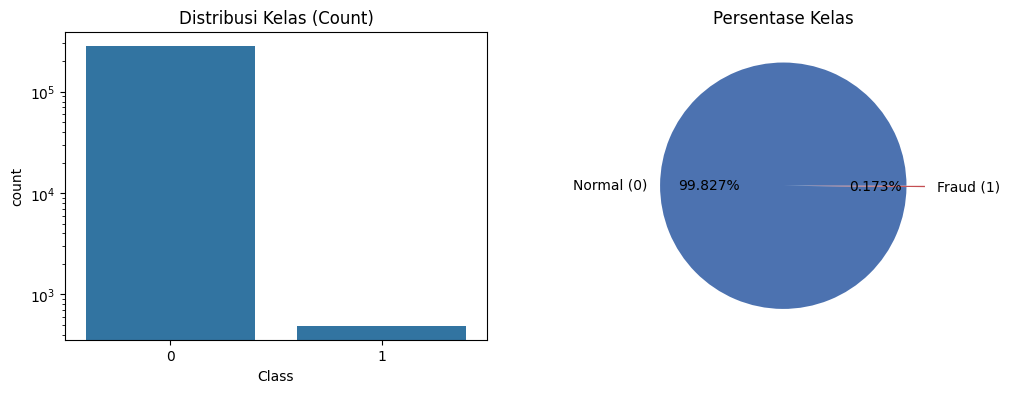

In [ ]:
counts = df['Class'].value_counts()
percent = df['Class'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Jumlah': counts, 'Persentase (%)': percent.round(4)}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='Class', data=df, ax=ax[0])
ax[0].set_title('Distribusi Kelas (Count)')
ax[0].set_yscale('log')
ax[1].pie(counts, labels=['Normal (0)', 'Fraud (1)'], autopct='%1.3f%%',
          colors=['#4c72b0', '#c44e52'], explode=(0, 0.15))
ax[1].set_title('Persentase Kelas')
plt.show()


In [7]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "Fraud:", y_train.sum(), f"({y_train.mean()*100:.3f}%)")
print("Test:", X_test.shape, "Fraud:", y_test.sum(), f"({y_test.mean()*100:.3f}%)")

Train: (227845, 30) Fraud: 394 (0.173%)
Test: (56962, 30) Fraud: 98 (0.172%)


In [9]:
results = {}

def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    res = {
        'Accuracy' : accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall'   : recall_score(y_true, pred),
        'F1-score' : f1_score(y_true, pred),
        'AUC-ROC'  : roc_auc_score(y_true, proba),
    }
    results[name] = res
    print({k: round(v, 4) for k, v in res.items()})
    print(classification_report(y_true, pred, target_names=['Normal', 'Fraud'], digits=4))
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
    plt.title(f'Confusion Matrix\n{name}')
    plt.xlabel('Prediksi'); plt.ylabel('Aktual')
    plt.show()

{'Accuracy': 0.9996, 'Precision': 0.962, 'Recall': 0.7755, 'F1-score': 0.8588, 'AUC-ROC': np.float64(0.951)}
              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56864
       Fraud     0.9620    0.7755    0.8588        98

    accuracy                         0.9996     56962
   macro avg     0.9808    0.8877    0.9293     56962
weighted avg     0.9995    0.9996    0.9995     56962



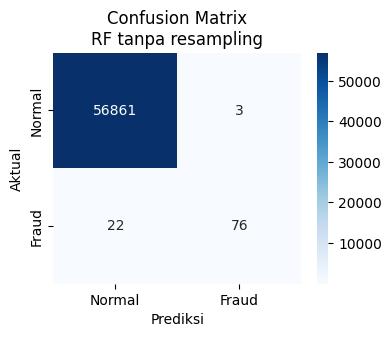

In [10]:
rf_base = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
rf_base.fit(X_train, y_train)

proba_rf_base = rf_base.predict_proba(X_test)[:, 1]
evaluate('RF tanpa resampling', y_test, proba_rf_base)


{0: 227451, 1: 22745}
{'Accuracy': 0.9995, 'Precision': 0.8977, 'Recall': 0.8061, 'F1-score': 0.8495, 'AUC-ROC': np.float64(0.9744)}
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9998     56864
       Fraud     0.8977    0.8061    0.8495        98

    accuracy                         0.9995     56962
   macro avg     0.9487    0.9030    0.9246     56962
weighted avg     0.9995    0.9995    0.9995     56962



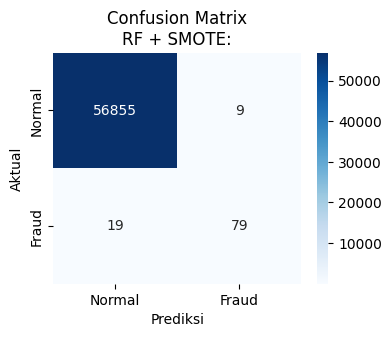

In [11]:
smote = SMOTE(sampling_strategy=0.1, random_state=SEED)
X_sm, y_sm = smote.fit_resample(X_train, y_train)
print(y_sm.value_counts().to_dict())

rf_smote = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
rf_smote.fit(X_sm, y_sm)

proba_rf_smote = rf_smote.predict_proba(X_test)[:,1]
evaluate('RF + SMOTE:', y_test, proba_rf_smote)

In [16]:
def train_balanced_ensemble(X_fit, y_fit, repeats=10, under_ratio=0.1, over_ratio=0.5):
    models = []
    for i in range(repeats):
        #UnderSample mayoritas
        rus = RandomUnderSampler(sampling_strategy=under_ratio, random_state=SEED + i)
        Xr, yr = rus.fit_resample(X_fit, y_fit)
        #Oversample Minoritas dg SMOTE
        sm = SMOTE(sampling_strategy=over_ratio, random_state=SEED + i)
        Xr, yr = sm.fit_resample(Xr, yr)

        xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, reg_lambda=1.5, tree_method='hist', eval_metric='auc', random_state=SEED + i, n_jobs=-1)
        lgb = LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.05, subsample=0.9, subsample_freq=1, colsample_bytree=0.9, reg_lambda=1.5, random_state=SEED + i, verbose=-1, n_jobs=-1)
        xgb.fit(Xr, yr)
        lgb.fit(Xr, yr)
        models += [xgb, lgb]
        print(f"Iterasi {i+1}/{repeats} selesai | data: {yr.value_counts().to_dict()}")
    return models

def predict_ensemble(models, X_):
    return np.mean([m.predict_proba(X_)[:,1] for m in models], axis=0)

Iterasi 1/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 2/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 3/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 4/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 5/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 6/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 7/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 8/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 9/10 selesai | data: {0: 3940, 1: 1970}
Iterasi 10/10 selesai | data: {0: 3940, 1: 1970}
{'Accuracy': 0.9972, 'Precision': 0.37, 'Recall': 0.8571, 'F1-score': 0.5169, 'AUC-ROC': np.float64(0.9855)}
              precision    recall  f1-score   support

      Normal     0.9998    0.9975    0.9986     56864
       Fraud     0.3700    0.8571    0.5169        98

    accuracy                         0.9972     56962
   macro avg     0.6849    0.9273    0.7578     56962
weighted avg     0.9987    0.9972    0.9978     56962



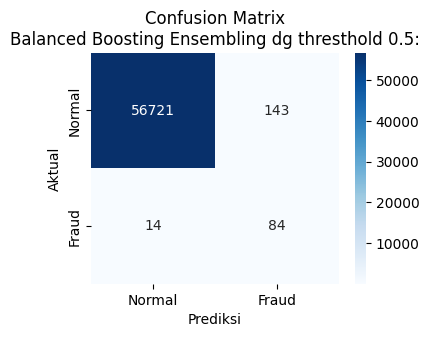

In [17]:
ens_models = train_balanced_ensemble(X_train, y_train, repeats=10)

proba_ens = predict_ensemble(ens_models, X_test)
evaluate("Balanced Boosting Ensembling dg thresthold 0.5:", y_test, proba_ens)

Iterasi 1/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 2/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 3/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 4/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 5/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 6/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 7/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 8/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 9/10 selesai | data: {0: 3150, 1: 1575}
Iterasi 10/10 selesai | data: {0: 3150, 1: 1575}
Threshold terbaik (validation): 0.9856 | F1 val: 0.8219
{'Accuracy': 0.9995, 'Precision': 0.8953, 'Recall': 0.7857, 'F1-score': 0.837, 'AUC-ROC': np.float64(0.9852)}
              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     56864
       Fraud     0.8953    0.7857    0.8370        98

    accuracy                         0.9995     56962
   macro avg     0.9475    0.8928    0.9183     56962
weighted avg     0.9995    0.9995    0.9995     56962



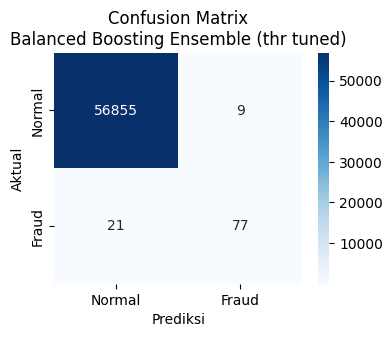

In [18]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

ens_models_v = train_balanced_ensemble(X_fit, y_fit, repeats=10)
proba_val = predict_ensemble(ens_models_v, X_val)

prec, rec, thr = precision_recall_curve(y_val, proba_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1s[:-1])]
print("Threshold terbaik (validation):", round(best_thr, 4), "| F1 val:", round(f1s.max(), 4))

proba_ens_v = predict_ensemble(ens_models_v, X_test)
evaluate('Balanced Boosting Ensemble (thr tuned)', y_test, proba_ens_v, threshold=best_thr)


,Accuracy,Precision,Recall,F1-score,AUC-ROC
RF tanpa resampling,0.9996,0.9620,0.7755,0.8588,0.9510
RF + SMOTE:,0.9995,0.8977,0.8061,0.8495,0.9744
Balanced Boosting Ensembling dg thresthold 0.5:,0.9972,0.3700,0.8571,0.5169,0.9855
Balanced Boosting Ensemble (thr tuned),0.9995,0.8953,0.7857,0.8370,0.9852


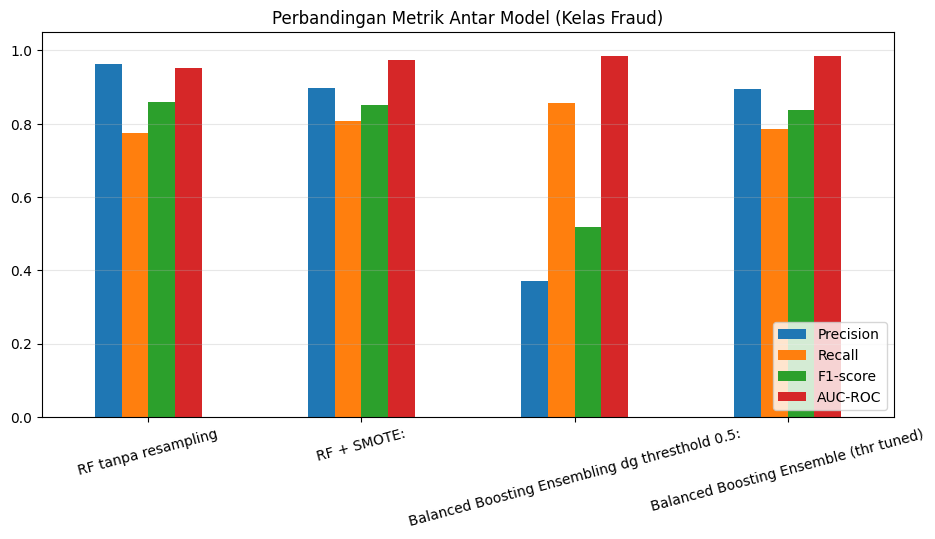

In [19]:
comp = pd.DataFrame(results).T.round(4)
display(comp)

comp[['Precision', 'Recall', 'F1-score', 'AUC-ROC']].plot(
    kind='bar', figsize=(11, 5), rot=15)
plt.title('Perbandingan Metrik Antar Model (Kelas Fraud)')
plt.ylim(0, 1.05); plt.legend(loc='lower right'); plt.grid(axis='y', alpha=.3)
plt.show()


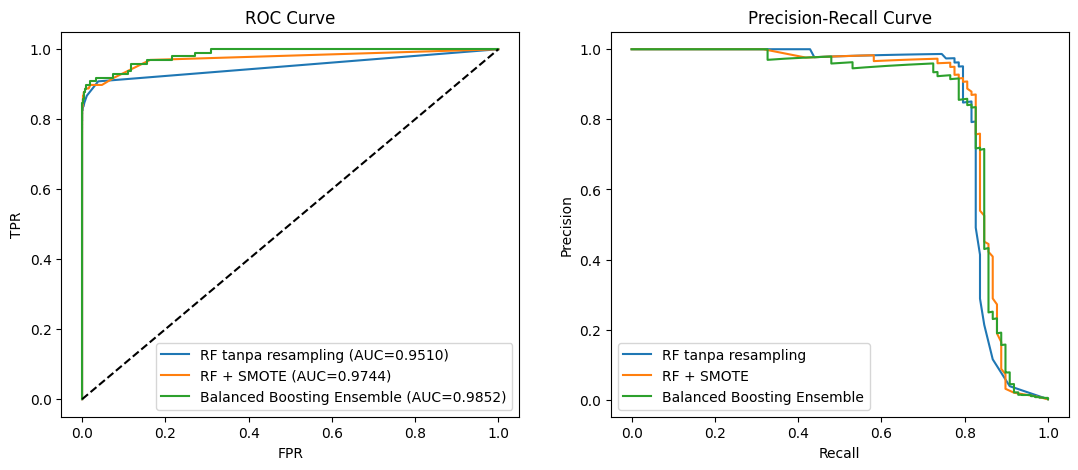

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in [('RF tanpa resampling', proba_rf_base),
                ('RF + SMOTE', proba_rf_smote),
                ('Balanced Boosting Ensemble', proba_ens_v)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.4f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_title('ROC Curve')
ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend()
ax[1].set_title('Precision-Recall Curve')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
plt.show()


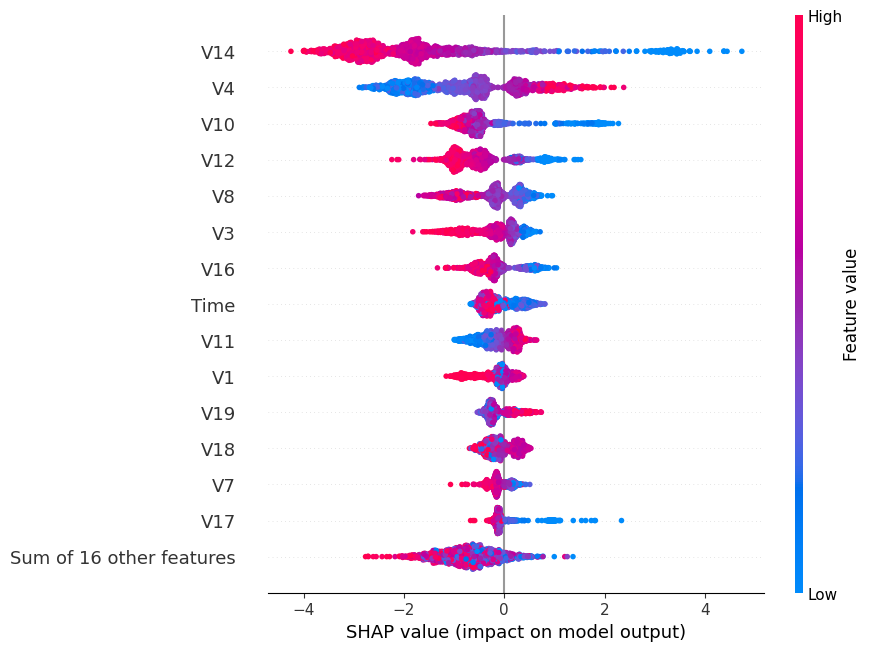

In [23]:
!pip install -q shap
import shap

model_shap = ens_models_v[0]

fraud_idx  = y_test[y_test == 1].index
normal_idx = y_test[y_test == 0].sample(1500, random_state=SEED).index
X_shap = X_test.loc[fraud_idx.union(normal_idx)]

explainer   = shap.TreeExplainer(model_shap)
shap_values = explainer(X_shap)

shap.plots.beeswarm(shap_values, max_display=15)
